   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

C:\Users\antony remane\AppData\Local\Temp\ipykernel_12512\4231741136.py:32: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  surv_anal=train.pivot_table(values='Survived',index='age_group',columns=['Sex','Pclass'],aggfunc='mean')*100


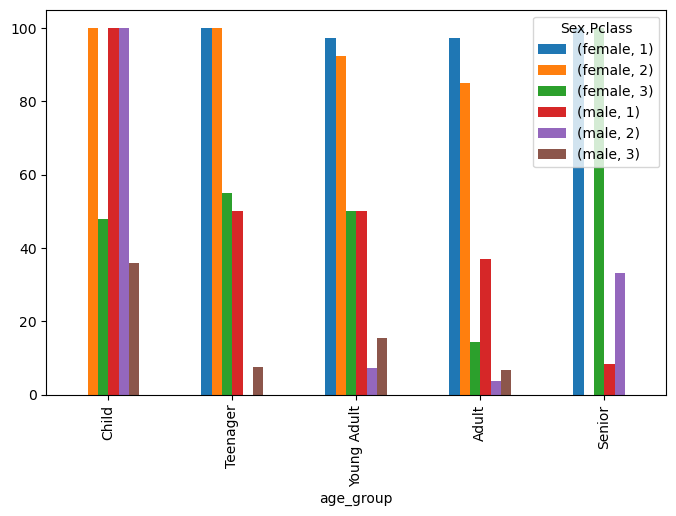

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
gender=pd.read_csv('gender_submission.csv')


print(train.head())
print(train.shape)
print(train.columns)
print(train.describe())
print(train.isnull().sum())
print("Duplicates")
print(train.duplicated().sum())
print(train.duplicated('PassengerId').sum())
print(train.duplicated('Ticket').sum())
survived=train['Survived'].sum()
total_count=len(train)
surv_percent=(survived/total_count)*100
print(f"Percentage of Survivor's: {surv_percent}")

# Groupby Survival
print("Grouby Survivals")
gender_survival=train.groupby('Sex')['Survived'].mean()*100
print(gender_survival)
pass_class_survival=train.groupby('Pclass')['Survived'].mean()*100
print(gender_survival)
train['age_group']=pd.cut(train['Age'],bins=[0, 12, 18, 35, 60, 100],labels=['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior'])
age_based_survival=train.groupby('age_group',observed=True)['Survived'].mean()*100
print(age_based_survival)
surv_anal=train.pivot_table(values='Survived',index='age_group',columns=['Sex','Pclass'],aggfunc='mean')*100
print(surv_anal)

# Visualizing Pivot_table
surv_anal.plot(kind='bar',figsize=(8,5))
plt.show()



In [80]:
# Handling Missing 
print(train['Age'].isnull().sum())
train['Age']=train['Age'].fillna(train['Age'].median())
print(train['Age'].isnull().sum())

177
0


In [81]:
train['Mapped_sex']=train['Sex'].map({
    "male":0,
    "female":1
})
train=pd.get_dummies(train,columns=['Embarked'],dtype=int)
print(train.head())


   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin    age_group  Mapped_sex  \
0      0         A/5 21171   7.2500   NaN  Young Adult           0   
1      0          PC 17599  71.2833   C85        Adult           1   
2      0  STON/O2. 3101282   7.9250   NaN  Young Adult           1   
3      0            113803  53.1000  C12

In [82]:
train.drop(columns=['Sex'], inplace=True)
print(train.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0      1      0   
2                             Heikkinen, Miss. Laina  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0      1      0   
4                           Allen, Mr. William Henry  35.0      0      0   

             Ticket     Fare Cabin    age_group  Mapped_sex  Embarked_C  \
0         A/5 21171   7.2500   NaN  Young Adult           0           0   
1          PC 17599  71.2833   C85        Adult           1           1   
2  STON/O2. 3101282   7.9250   NaN  Young Adult           1           0   
3            113803  53.10

In [83]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import (precision_score,recall_score,f1_score)
from sklearn.model_selection import cross_val_score
X = train[[
    'Pclass',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'Mapped_sex',
    'Embarked_C',
    'Embarked_Q',
    'Embarked_S'
]]
y=train['Survived']
    
X_train,X_test,Y_train,Y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
model=DecisionTreeClassifier(random_state=42)
model.fit(X_train,Y_train)
y_pred=model.predict(X_test)
accuracy=accuracy_score(Y_test,y_pred)
print(f"Accuracy: {accuracy}")

cm = confusion_matrix(Y_test, y_pred)

print(cm)

print("Precision:", precision_score(Y_test, y_pred))
print("Recall:", recall_score(Y_test, y_pred))
print("F1-score:", f1_score(Y_test, y_pred))

# Cross Validation
Dts=cross_val_score(model,X_train,Y_train,cv=5,scoring="accuracy")
print(Dts)
print(Dts.mean())

Accuracy: 0.8212290502793296
[[97 13]
 [19 50]]
Precision: 0.7936507936507936
Recall: 0.7246376811594203
F1-score: 0.7575757575757576
[0.76923077 0.73426573 0.8028169  0.80985915 0.83802817]
0.7908401457697233


In [84]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix 
import matplotlib.pyplot as plt
rf_model=RandomForestClassifier(n_estimators=200,random_state=42)
rf_model.fit(X_train,Y_train)
rf_pred=rf_model.predict(X_test)
rf_accur=accuracy_score(Y_test,rf_pred)
print(f"{rf_model.n_estimators} RF Accuracy: {rf_accur}")
print(f"Confusion Matrix: \n{confusion_matrix(Y_test,rf_pred)}")
print("Precision:", precision_score(Y_test, rf_pred))
print("Recall:", recall_score(Y_test, rf_pred))
print("F1-score:", f1_score(Y_test, rf_pred))

# Cross Validation
rfs=cross_val_score(rf_model,X_train,Y_train,cv=5,scoring="accuracy")
print(rfs)
print(rfs.mean())

200 RF Accuracy: 0.8212290502793296
Confusion Matrix: 
[[98 12]
 [20 49]]
Precision: 0.8032786885245902
Recall: 0.7101449275362319
F1-score: 0.7538461538461538
[0.77622378 0.71328671 0.83098592 0.84507042 0.8028169 ]
0.7936767457894218


   PassengerId  Pclass                                          Name     Sex  \
0          892       3                              Kelly, Mr. James    male   
1          893       3              Wilkes, Mrs. James (Ellen Needs)  female   
2          894       2                     Myles, Mr. Thomas Francis    male   
3          895       3                              Wirz, Mr. Albert    male   
4          896       3  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female   

    Age  SibSp  Parch   Ticket     Fare Cabin Embarked  
0  34.5      0      0   330911   7.8292   NaN        Q  
1  47.0      1      0   363272   7.0000   NaN        S  
2  62.0      0      0   240276   9.6875   NaN        Q  
3  27.0      0      0   315154   8.6625   NaN        S  
4  22.0      1      1  3101298  12.2875   NaN        S  


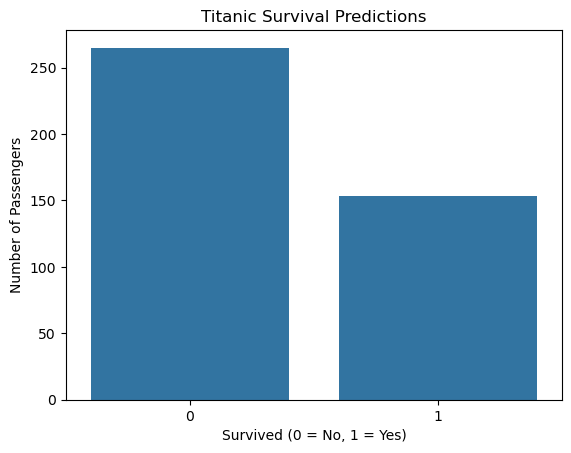

In [89]:
# Testing The Model
test=pd.read_csv('test.csv')
print(test.head())

# Fill missing values using training data medians
test['Age'] = test['Age'].fillna(train['Age'].median())
test['Fare'] = test['Fare'].fillna(train['Fare'].median())

test['Mapped_sex']=test['Sex'].map({
    'male':0,
    'female':1
})
test=pd.get_dummies(test,columns=['Embarked'],dtype=int)
X_competition=test.reindex(columns=X.columns,fill_value=0)

final_model=RandomForestClassifier(n_estimators=200,random_state=42)
final_model.fit(X,y)
predictions=final_model.predict(X_competition)
import seaborn as sns

sns.countplot(x=predictions)
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.title("Titanic Survival Predictions")
plt.show()

In [ ]:
submission=pd.DataFrame({
    'PassengerId':test['PassengerId'],
    'Survived':predictions
})
submission.to_csv('submission.csv',index=False)
print(submission.head())
print(submission.shape)
print(submission.isnull().sum())